In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
np.set_printoptions(precision=3,suppress=True)

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Stałe ziarno: wyniki kolejnych uruchomień są porównywalne
# (bez niego MAE jednej sieci waha się między uruchomieniami o ~0,1 MPG).
tf.keras.utils.set_random_seed(42)


I0000 00:00:1792578856.905188   22361 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792578856.978903   22361 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792578858.245739   22361 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# --- DATA LOADING (online) + OFFLINE FALLBACK (synthetic) ---
# Ten notebook oryginalnie pobiera Auto MPG z UCI. W środowiskach bez internetu pojawia się błąd "brak źródła".
# Poniżej jest bezpieczny fallback: jeśli pobranie się nie uda, generujemy syntetyczny zbiór o podobnej strukturze.

import numpy as np
import pandas as pd

def make_synthetic_auto_mpg(n: int = 398, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    # Zmienne dyskretne
    cylinders = rng.choice([3, 4, 5, 6, 8], size=n, p=[0.02, 0.5, 0.03, 0.25, 0.20])
    model_year = rng.integers(70, 83, size=n)  # 70..82
    origin = rng.choice(["USA", "Europe", "Japan"], size=n, p=[0.62, 0.18, 0.20])

    # Displacement rośnie z cylindrami
    displacement = (
        cylinders * rng.normal(35, 6, size=n)
        + rng.normal(40, 25, size=n)
    )
    displacement = np.clip(displacement, 60, 460)

    # Horsepower zależny od displacement i cyl
    horsepower = (
        0.35 * displacement
        + 6 * (cylinders - 4)
        + rng.normal(0, 18, size=n)
    )
    horsepower = np.clip(horsepower, 45, 240)

    # Weight zależny od displacement i origin
    origin_weight_shift = np.select(
        [origin == "USA", origin == "Europe", origin == "Japan"],
        [250, -120, -80],
        default=0
    )
    weight = (
        8.5 * displacement
        + origin_weight_shift
        + rng.normal(0, 250, size=n)
        + 100 * (cylinders - 4)
    )
    weight = np.clip(weight, 1500, 5200)

    # Acceleration: większa masa = zwykle gorsze przyspieszenie (większy czas)
    acceleration = (
        22 - 0.0018 * weight + rng.normal(0, 1.2, size=n)
    )
    acceleration = np.clip(acceleration, 8, 25)

    # MPG: spada z masą/horsepower/displacement, rośnie z rokiem modelowym (postęp technologiczny)
    origin_eff = np.select(
        [origin == "USA", origin == "Europe", origin == "Japan"],
        [0.0, 2.2, 2.8],
        default=0.0
    )
    mpg = (
        58
        - 0.0048 * weight
        - 0.045 * horsepower
        - 0.010 * displacement
        + 0.55 * (model_year - 70)
        + origin_eff
        + rng.normal(0, 2.2, size=n)
    )
    mpg = np.clip(mpg, 8, 50)

    df = pd.DataFrame({
        "MPG": mpg.round(2),
        "Cylinders": cylinders.astype(int),
        "Displacement": displacement.round(1),
        "Horsepower": horsepower.round(1),
        "Weight": weight.round(1),
        "Acceleration": acceleration.round(2),
        "Model Year": model_year.astype(int),
        "Origin": origin
    })
    return df

def load_auto_mpg_mirror() -> pd.DataFrame:
    """Te same dane UCI (ta sama kolejność wierszy) z repozytorium seaborn-data na GitHubie."""
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
    raw = pd.read_csv(url)
    ds = raw.rename(columns={"mpg": "MPG", "cylinders": "Cylinders", "displacement": "Displacement",
                             "horsepower": "Horsepower", "weight": "Weight", "acceleration": "Acceleration",
                             "model_year": "Model Year", "origin": "Origin"}).drop(columns="name").dropna()
    ds["Origin"] = ds["Origin"].map({"usa": "USA", "europe": "Europe", "japan": "Japan"})
    return ds

def load_auto_mpg() -> pd.DataFrame:
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
    column_names = ["MPG","Cylinders","Displacement","Horsepower","Weight","Acceleration","Model Year","Origin"]

    try:
        raw = pd.read_csv(
            url,
            names=column_names,
            na_values="?",
            comment="\t",
            sep=" ",
            skipinitialspace=True,
        )
        ds = raw.copy().dropna()
        # origin w oryginale jest kodem 1/2/3
        if pd.api.types.is_numeric_dtype(ds["Origin"]):  # działa też w pandas 3.x
            ds["Origin"] = ds["Origin"].map({1: "USA", 2: "Europe", 3: "Japan"})
        print("✅ Źródło danych: UCI.")
        return ds
    except Exception as e:
        print("⚠️ UCI niedostępne:", repr(e)[:120], "→ próbuję lustra seaborn-data (GitHub).")
        try:
            ds = load_auto_mpg_mirror()
            print("✅ Źródło danych: lustro seaborn-data (identyczne z UCI).")
            return ds
        except Exception as e2:
            print("⚠️ Lustro też niedostępne. Używam syntetycznego zbioru Auto MPG.")
            print("   Powód:", repr(e2))
            return make_synthetic_auto_mpg()

dataset = load_auto_mpg()
dataset.head()


⚠️ UCI niedostępne: URLError(OSError('Tunnel connection failed: 403 Forbidden')) → próbuję lustra seaborn-data (GitHub).


✅ Źródło danych: lustro seaborn-data (identyczne z UCI).


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504,12.0,70,USA
1,15.0,8,350.0,165.0,3693,11.5,70,USA
2,18.0,8,318.0,150.0,3436,11.0,70,USA
3,16.0,8,304.0,150.0,3433,12.0,70,USA
4,17.0,8,302.0,140.0,3449,10.5,70,USA


In [3]:
# (dane wczytane w poprzedniej komórce)


In [4]:
dataset.tail()


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790,15.6,82,USA
394,44.0,4,97.0,52.0,2130,24.6,82,Europe
395,32.0,4,135.0,84.0,2295,11.6,82,USA
396,28.0,4,120.0,79.0,2625,18.6,82,USA
397,31.0,4,119.0,82.0,2720,19.4,82,USA


In [5]:
dataset.isna().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [6]:
# dataset = dataset.dropna()  # (opcjonalnie) - u nas już bez braków


In [7]:
dataset.isna().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      0
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [8]:
# Origin bywa kodem 1/2/3 (UCI) albo tekstem (nasz fallback).
if pd.api.types.is_numeric_dtype(dataset["Origin"]):  # działa też w pandas 3.x
    dataset["Origin"] = dataset["Origin"].map({1:"USA", 2:"Europe", 3:"Japan"})
dataset["Origin"].value_counts()


Origin
USA       245
Japan      79
Europe     68
Name: count, dtype: int64

In [9]:
dataset = pd.get_dummies(dataset,columns=['Origin'],prefix='',prefix_sep='')
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
393,27.0,4,140.0,86.0,2790,15.6,82,False,False,True
394,44.0,4,97.0,52.0,2130,24.6,82,True,False,False
395,32.0,4,135.0,84.0,2295,11.6,82,False,False,True
396,28.0,4,120.0,79.0,2625,18.6,82,False,False,True
397,31.0,4,119.0,82.0,2720,19.4,82,False,False,True


In [10]:
train_dataset = dataset.sample(frac=0.8,random_state=0)
test_dataset = dataset.drop(train_dataset.index)

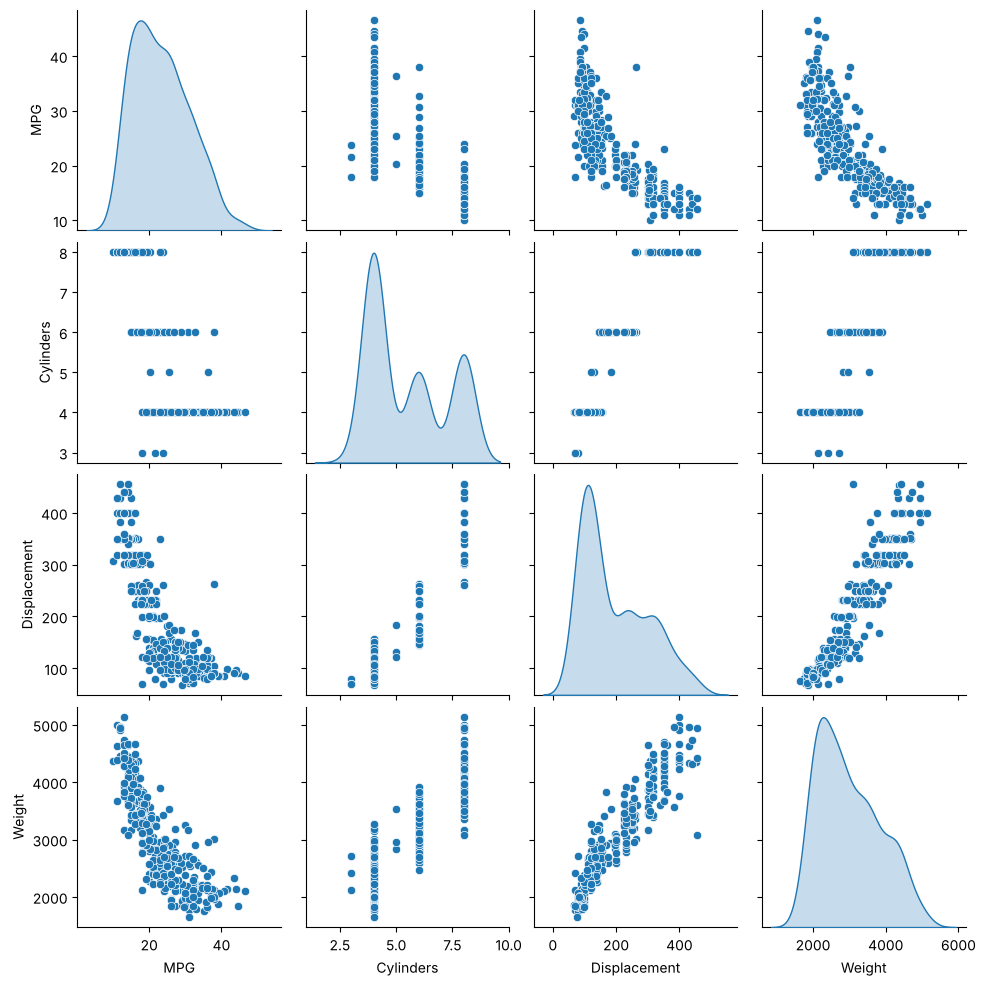

In [11]:
sns.pairplot(train_dataset[['MPG','Cylinders','Displacement','Weight']],diag_kind='kde')

In [12]:
train_dataset.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
MPG,314.0,23.310510,7.728652,10.0,17.00,22.0,28.95,46.6
Cylinders,314.0,5.477707,1.699788,3.0,4.00,4.0,8.00,8.0
Displacement,314.0,195.318471,104.331589,68.0,105.50,151.0,265.75,455.0
Horsepower,314.0,104.869427,38.096214,46.0,76.25,94.5,128.00,225.0
Weight,314.0,2990.251592,843.898596,1649.0,2256.50,2822.5,3608.00,5140.0
Acceleration,314.0,15.559236,2.789230,8.0,13.80,15.5,17.20,24.8
Model Year,314.0,75.898089,3.675642,70.0,73.00,76.0,79.00,82.0


In [13]:
train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('MPG')
test_labels = test_features.pop('MPG')

In [14]:
train_dataset.describe().transpose()[['mean','std']]

,mean,std
MPG,23.310510,7.728652
Cylinders,5.477707,1.699788
Displacement,195.318471,104.331589
Horsepower,104.869427,38.096214
Weight,2990.251592,843.898596
Acceleration,15.559236,2.789230
Model Year,75.898089,3.675642


In [15]:
normalizer = tf.keras.layers.Normalization(axis=-1)

In [16]:
normalizer.adapt(np.array(train_features))

In [17]:
print(normalizer.mean.numpy())

[[   5.478  195.318  104.869 2990.252   15.559   75.898    0.178    0.197
     0.624]]


In [18]:
first = np.array(train_features[:1])

In [19]:
with np.printoptions(precision=2,suppress=True):
    print(f'pierwszy przypadek: {first}')
    print(f'po normalizacji: {normalizer(first.astype(float)).numpy()}')

pierwszy przypadek: [[4 90.0 75.0 2125 14.5 74 False False True]]
po normalizacji: [[-0.87 -1.01 -0.79 -1.03 -0.38 -0.52 -0.47 -0.5   0.78]]


In [20]:
#regresja liniowa z jedną zmienną
#y = ax+b

horsepower = np.array(train_features['Horsepower'])
horsepower_normalizer = layers.Normalization(input_shape=[1,],axis=None)
horsepower_normalizer.adapt(horsepower)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
horsepower_model = tf.keras.Sequential([
    horsepower_normalizer,
    layers.Dense(units=1)
])

horsepower_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 3 (16.00 B)

In [22]:
horsepower_model.predict(horsepower[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


array([[-0.974],
       [-0.55 ],
       [ 1.798],
       [-1.366],
       [-1.235],
       [-0.485],
       [-1.464],
       [-1.235],
       [-0.322],
       [-0.55 ]], dtype=float32)

In [23]:
horsepower_model.compile(
    optimizer=tf.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error'
)

In [24]:
%%time
history = horsepower_model.fit(
    train_features['Horsepower'],
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 9.6 s, sys: 431 ms, total: 10 s
Wall time: 10.2 s


In [25]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,val_loss,epoch
95,3.803593,4.190416,95
96,3.803359,4.191695,96
97,3.803250,4.193234,97
98,3.803803,4.189746,98
99,3.803158,4.195340,99


In [26]:
import matplotlib.pyplot as plt

In [27]:
def plot_loss(history):
    plt.plot(history.history['loss'],label='loss')
    plt.plot(history.history['val_loss'],label='val_loss')
    plt.ylim([0,10])
    plt.xlabel('Epoch')
    plt.ylabel('Error[MPG]')
    plt.legend()
    plt.grid(True)

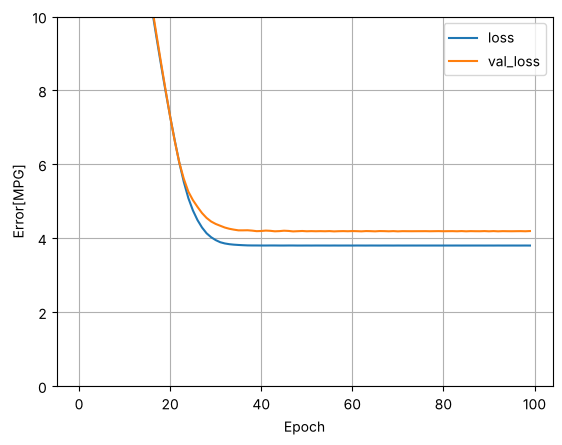

In [28]:
plot_loss(history)

In [29]:
test_result = {}
test_result['horsepower_model'] = horsepower_model.evaluate(
    test_features['Horsepower'],
    test_labels,
    verbose=0
)

In [30]:
x = tf.linspace(0.0,250,251)
y = horsepower_model.predict(x)

1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [31]:
def plot_horsepower(x,y):
    plt.scatter(train_features['Horsepower'],train_labels,label='Data')
    plt.plot(x,y,color='k',label='Predictions')
    plt.xlabel('Horsepower')
    plt.ylabel('MPG')
    plt.legend()

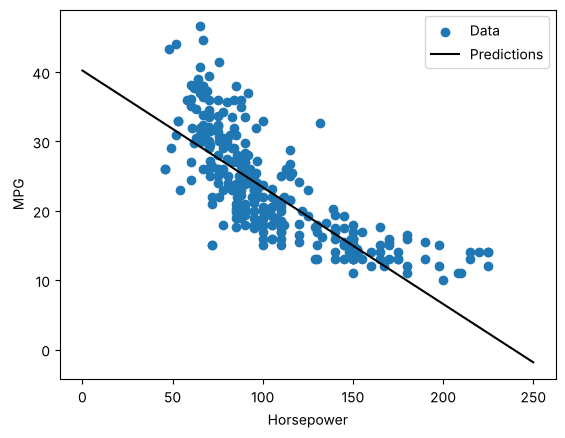

In [32]:
plot_horsepower(x,y)

In [33]:
linear_model = tf.keras.Sequential([
    normalizer,
    layers.Dense(units=1)
])
linear_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (314, 9)               │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (80.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 19 (80.00 B)

In [34]:
linear_model.compile(
    optimizer=tf.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error'
)

In [35]:
%%time
history = linear_model.fit(
    train_features,
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 10.2 s, sys: 380 ms, total: 10.6 s
Wall time: 10.5 s


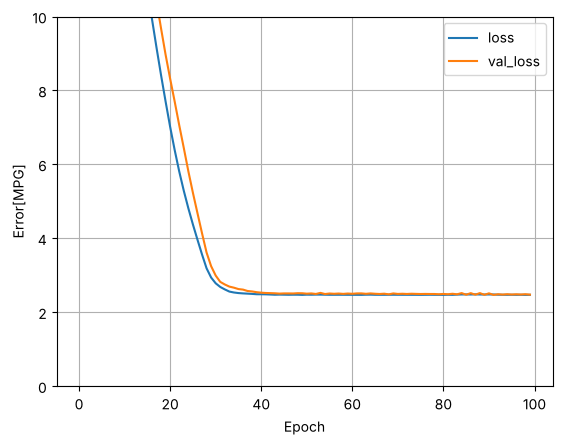

In [36]:
plot_loss(history)

In [37]:
test_result['linear_model'] = linear_model.evaluate(
    test_features,
    test_labels,
    verbose=0
)

In [38]:
#regresja z głędoką siecią neuronową DNN
def build_and_compile(norm):
    model = keras.Sequential([
        norm,
        layers.Dense(64,activation='relu'),
        layers.Dense(64,activation='relu'),
        layers.Dense(1)
    ])
    model.compile(loss='mean_absolute_error',optimizer=tf.keras.optimizers.Adam(0.001))
    return model

In [39]:
#regresja z użyciem DNN i pojedynczego wejścia
dnn_horsepower_model = build_and_compile(horsepower_normalizer)

In [40]:
dnn_horsepower_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,356 (17.02 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 3 (16.00 B)

In [41]:
%%time
history = dnn_horsepower_model.fit(
    train_features['Horsepower'],
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 10.2 s, sys: 474 ms, total: 10.7 s
Wall time: 10.6 s


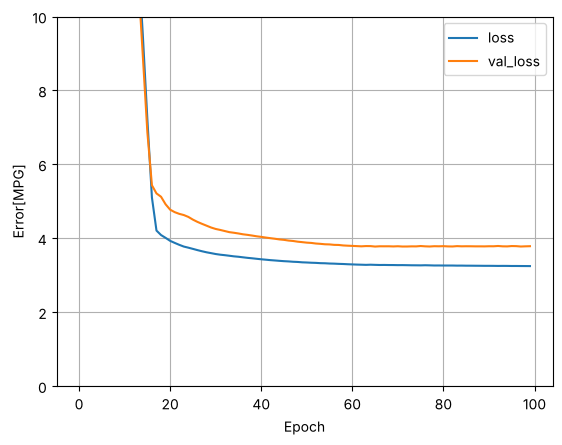

In [42]:
plot_loss(history)

In [43]:
test_result['dnn_horsepower_model'] = dnn_horsepower_model.evaluate(
    test_features['Horsepower'],
    test_labels,
    verbose=0
)

1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


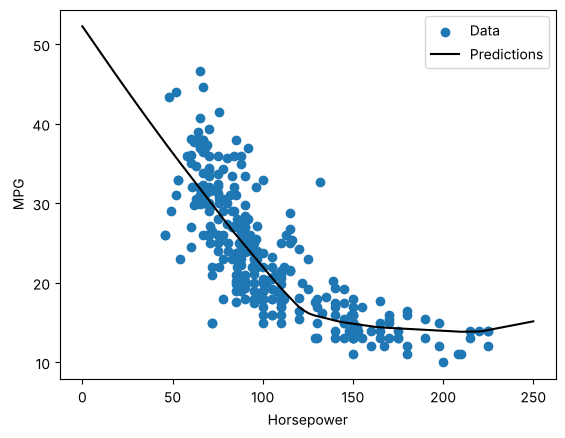

In [44]:
x = tf.linspace(0.0,250,251)
y = dnn_horsepower_model.predict(x)
plot_horsepower(x,y)

In [45]:
#regresja przy użyciu dnn i wielu danych wejściowych
dnn_model = build_and_compile(normalizer)
dnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (80.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 19 (80.00 B)

In [46]:
%%time
history = dnn_model.fit(
    train_features,
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 10.2 s, sys: 437 ms, total: 10.6 s
Wall time: 10.7 s


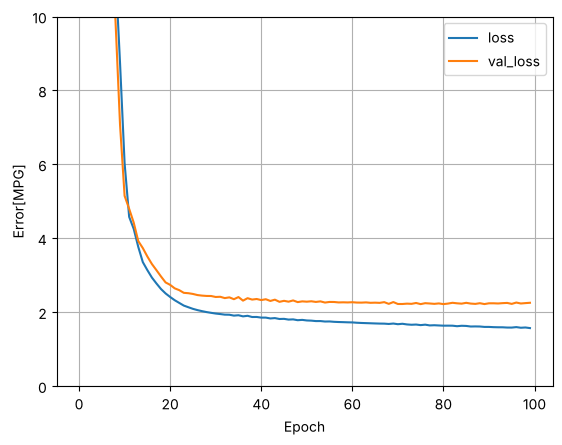

In [47]:
plot_loss(history)

In [48]:
test_result['dnn_model'] = dnn_model.evaluate(
    test_features,
    test_labels,
    verbose=0
)

In [49]:
#regresja z głędoką siecią neuronową DNN
def build_and_compile_biggest(norm):
    model = keras.Sequential([
        norm,
        layers.Dense(128,activation='relu'),
        layers.Dense(512,activation='relu'),
        layers.Dense(512,activation='relu'),
        layers.Dense(64,activation='relu'),
        layers.Dense(1)
    ])
    model.compile(loss='mean_absolute_error',optimizer=tf.keras.optimizers.Adam(0.001))
    return model

In [50]:
#regresja przy użyciu dnn - z większą ilością warstw i wielu danych wejściowych
dnn_model_big = build_and_compile_biggest(normalizer)
dnn_model_big.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19 (80.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 19 (80.00 B)

In [51]:
%%time
history = dnn_model_big.fit(
    train_features,
    train_labels,
    epochs=100,
    verbose=0,
    validation_split=0.2
)

CPU times: user 16.6 s, sys: 1.19 s, total: 17.8 s
Wall time: 18 s


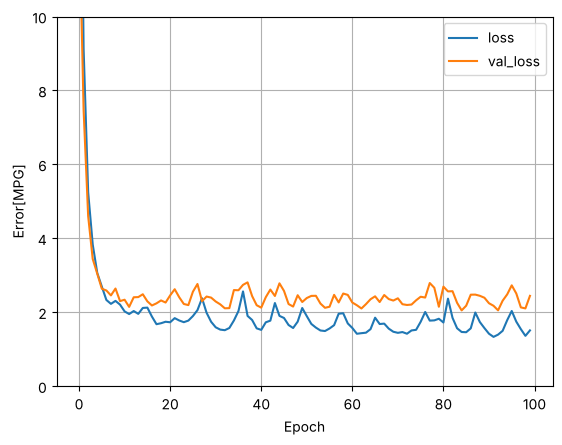

In [52]:
plot_loss(history)

In [53]:
test_result['dnn_model_big'] = dnn_model_big.evaluate(
    test_features,
    test_labels,
    verbose=0
)

## Krok dalej: czy da się zejść z siecią poniżej 1,7 MPG?

**Najpierw ważna obserwacja.** `dnn_model` dał u Ciebie 1,72, ale ta sama sieć, trenowana 10 razy z różnymi ziarnami losowości, daje na tym samym teście od 1.64 do 1.80 (średnio 1.709), a poniżej 1,7 schodzi w 5 na 10 przebiegów. Próg 1,7 leży więc **w środku szumu** tej sieci — jeden przebieg poniżej 1,7 niczego nie dowodzi. Uczciwe pytanie brzmi: czy jakaś sieć jest **średnio** lepsza, i czy wybrano ją **bez patrzenia na test**.

**Protokół (spisany przed obliczeniami, SHA-256 `a4430e6d…`).** Pięć wariantów, każdy jako pojedyncza sieć i jako zespół 5 sieci (średnia predykcji). Wybór wyłącznie 5-krotną walidacją krzyżową na 314 autach treningowych:

| Wariant | Opis | CV-MAE (1 sieć) | CV-MAE (zespół 5) |
|---|---|---|---|
| A | Twoja `dnn_model`: [64, 64], 100 epok | 2.060 | 2.018 |
| B | A, ale cel = 100/MPG (galony na 100 mil) | 2.124 | 2.034 |
| C | [64, 64] + EarlyStopping (patience 50, do 1000 epok) | 2.070 | **2.014** |
| D | B + C | 2.132 | 2.038 |
| E | D + [128, 64], L2 1e-3, Dropout 0,1 | 2.199 | 2.124 |

Regułę „najniższe CV-MAE” wygrał **zespół C** (`dnn_es_ensemble5`), ale tylko o 0.004 przed **zespołem A** (`dnn_ensemble5` = 5 × Twoja `dnn_model`) — w praktyce remis. Wyraźny i powtarzalny efekt daje jedno: **uśrednianie kilku sieci**. Transformacja celu, większa sieć i regularyzacja pogarszały wynik.

Poniżej trenujemy oba zespoły.

In [54]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, median_absolute_error,
                             max_error, r2_score)

X_train = train_features.astype('float32').values
X_test  = test_features.astype('float32').values
y_train = train_labels.astype('float32').values
y_test  = test_labels.astype('float32').values

def build_dnn(norm, units=(64, 64), lr=1e-3):
    model = keras.Sequential([norm] + [layers.Dense(u, activation='relu') for u in units] + [layers.Dense(1)])
    model.compile(loss='mean_absolute_error', optimizer=tf.keras.optimizers.Adam(lr))
    return model

class EnsembleRegressor:
    """Zespół sieci: predykcja = średnia predykcji członków."""
    def __init__(self, models):
        self.models = models
    def predict(self, X, verbose=0):
        X = tf.constant(np.asarray(X, dtype='float32'))
        return np.mean([m(X, training=False).numpy().ravel() for m in self.models], axis=0)
    def count_params(self):
        return sum(m.count_params() for m in self.models)

def train_ensemble(n_models=5, seed0=1000, early_stopping=False, max_epochs=1000, patience=50, verbose=True):
    """early_stopping=False → 5 × dnn_model (100 epok); True → do 1000 epok z EarlyStopping."""
    models, histories = [], []
    for i in range(n_models):
        tf.keras.utils.set_random_seed(seed0 + i)
        m = build_dnn(normalizer)
        if early_stopping:
            cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
                                                   restore_best_weights=True)]
            h = m.fit(X_train, y_train, epochs=max_epochs, validation_split=0.2, verbose=0, callbacks=cb)
        else:
            h = m.fit(X_train, y_train, epochs=100, validation_split=0.2, verbose=0)
        if verbose:
            best = int(np.argmin(h.history['val_loss'])) + 1
            print(f"sieć {i+1}/{n_models}: {len(h.history['loss'])} epok, "
                  f"najlepsza epoka {best}, val MAE {min(h.history['val_loss']):.3f}")
        models.append(m)
        histories.append(h)
    return EnsembleRegressor(models), histories

In [55]:
%%time
print('Zespół A: 5 × dnn_model')
dnn_ensemble, ens_histories = train_ensemble(n_models=5, seed0=1000, early_stopping=False)
print('\nZespół C: 5 × DNN 64-64 + EarlyStopping')
dnn_es_ensemble, es_histories = train_ensemble(n_models=5, seed0=1000, early_stopping=True)

Zespół A: 5 × dnn_model


sieć 1/5: 100 epok, najlepsza epoka 85, val MAE 2.144


sieć 2/5: 100 epok, najlepsza epoka 100, val MAE 2.229


sieć 3/5: 100 epok, najlepsza epoka 99, val MAE 2.274


sieć 4/5: 100 epok, najlepsza epoka 92, val MAE 2.143


...

sieć 1/5: 135 epok, najlepsza epoka 85, val MAE 2.144


sieć 2/5: 325 epok, najlepsza epoka 275, val MAE 2.083


sieć 3/5: 159 epok, najlepsza epoka 109, val MAE 2.273


sieć 4/5: 248 epok, najlepsza epoka 198, val MAE 2.086


sieć 5/5: 389 epok, najlepsza epoka 339, val MAE 2.145
CPU times: user 3min 4s, sys: 8.77 s, total: 3min 13s
Wall time: 3min 12s


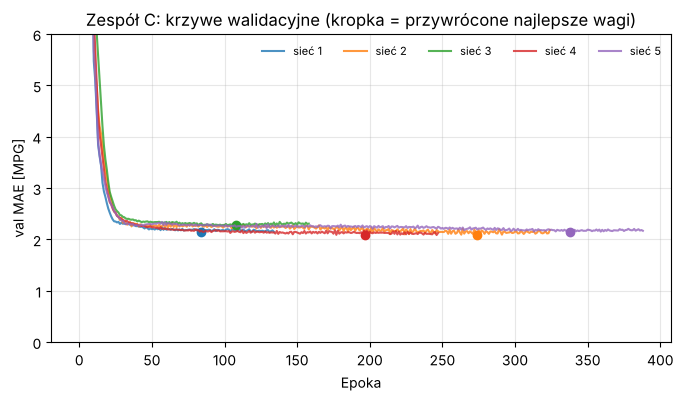

In [56]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, h in enumerate(es_histories):
    line, = ax.plot(h.history['val_loss'], lw=1.5, alpha=0.8, label=f'sieć {i+1}')
    best = int(np.argmin(h.history['val_loss']))
    ax.plot(best, h.history['val_loss'][best], 'o', ms=6, color=line.get_color())
ax.set_ylim(0, 6); ax.set_xlabel('Epoka'); ax.set_ylabel('val MAE [MPG]')
ax.set_title('Zespół C: krzywe walidacyjne (kropka = przywrócone najlepsze wagi)')
ax.grid(True, alpha=0.3); ax.legend(ncol=5, fontsize=8, frameon=False)
plt.show()

In [57]:
test_result['dnn_ensemble5'] = mean_absolute_error(y_test, dnn_ensemble.predict(X_test))
test_result['dnn_es_ensemble5'] = mean_absolute_error(y_test, dnn_es_ensemble.predict(X_test))
print(f"MAE zespołu A (5 × dnn_model):     {test_result['dnn_ensemble5']:.3f} MPG")
print(f"MAE zespołu C (5 × DNN + ES):      {test_result['dnn_es_ensemble5']:.3f} MPG")
print("Uwaga: to jeden przebieg; rozrzut między przebiegami pokazuje tabela poniżej.")

MAE zespołu A (5 × dnn_model):     1.716 MPG
MAE zespołu C (5 × DNN + ES):      1.781 MPG
Uwaga: to jeden przebieg; rozrzut między przebiegami pokazuje tabela poniżej.


### Wynik z 10 powtórzeń (różne ziarna, ten sam test 78 aut)

| Model | MAE: średnia ± odch. | zakres | przebiegi < 1,7 |
|---|---|---|---|
| **Zespół A: 5 × `dnn_model`** (`dnn_ensemble5`) | 1.680 ± 0.023 | 1.646–1.717 | 8/10 |
| `dnn_model` (Twoja sieć) | 1.709 ± 0.066 | 1.635–1.799 | 5/10 |
| Zespół C: 5 × DNN + EarlyStopping (wybrany przez CV) | 1.726 ± 0.030 | 1.684–1.783 | 1/10 |
| Las losowy (punkt odniesienia) | 1.767 ± 0.019 | 1.730–1.799 | 0/10 |
| Pojedyncza DNN + EarlyStopping | 1.780 ± 0.083 | 1.672–1.921 | 3/10 |
| Gradient boosting (punkt odniesienia) | 1.828 ± 0.010 | 1.811–1.846 | 0/10 |

**Werdykt według protokołu: porażka.** Model wybrany walidacją krzyżową (zespół C) ma średnio 1.726 MPG — nie schodzi poniżej 1,70 i nie jest lepszy od `dnn_model` (Wilcoxon p = 0.75).

**Co jednak widać (opisowo, wskazane już po obejrzeniu testu):** zespół A, czyli po prostu 5 kopii Twojej sieci z uśrednionymi predykcjami, ma średnio **1.680** i jest poniżej 1,7 w **8 na 10** przebiegów. Najważniejsze: jego rozrzut spada z ±0.066 do ±0.023 — wynik przestaje zależeć od szczęścia. Średnia przewaga 0.029 MPG nad pojedynczą siecią nie jest jednak statystycznie pewna (Wilcoxon p ≈ 0,19 przy 10 parach) i trzeba ją potwierdzić na innych podziałach danych.

Obie sieci-zespoły są lepsze od lasu losowego i boostingu na tym podziale, więc 1,7 jest blisko tego, co te 9 cech daje na 78 autach testowych.

**Test poza zakresem treningu (opisowy):** trening na rocznikach 70–79, test na 80–82 — `dnn_model` 4.88 ± 0.23, zespół C 4.26 ± 0.08 MPG. Tu EarlyStopping wyraźnie pomaga, ale błąd każdego modelu rośnie ponad dwukrotnie: auta z lat 80. są oszczędniejsze, niż wynikałoby z danych z lat 70.

Ustaw `RUN_STABILITY = True`, żeby powtórzyć ten pomiar u siebie (~20–30 min w Colabie).

In [58]:
MEASURED_10_RUNS = {
    'dnn_model': [1.643, 1.775, 1.797, 1.799, 1.647, 1.767, 1.715, 1.651, 1.659, 1.635],
    'dnn_ensemble5': [1.717, 1.650, 1.694, 1.692, 1.692, 1.646, 1.683, 1.707, 1.660, 1.660],
    'dnn_es_ensemble5': [1.783, 1.700, 1.723, 1.714, 1.724, 1.715, 1.708, 1.734, 1.779, 1.684],
    'random_forest': [1.730, 1.749, 1.759, 1.768, 1.756, 1.785, 1.777, 1.799, 1.762, 1.786],
    'gradient_boosting': [1.840, 1.823, 1.846, 1.818, 1.826, 1.820, 1.825, 1.836, 1.811, 1.834],
}

RUN_STABILITY = False   # True → 10 powtórzeń obu zespołów i dnn_model (nadpisze liczby powyżej)

if RUN_STABILITY:
    from scipy.stats import wilcoxon
    runs = {'dnn_model': [], 'dnn_ensemble5': [], 'dnn_es_ensemble5': []}
    for r in range(10):
        tf.keras.utils.set_random_seed(1000 + r)
        b = build_dnn(normalizer)
        b.fit(X_train, y_train, epochs=100, validation_split=0.2, verbose=0)
        runs['dnn_model'].append(mean_absolute_error(y_test, b(tf.constant(X_test), training=False).numpy().ravel()))
        for key, es in [('dnn_ensemble5', False), ('dnn_es_ensemble5', True)]:
            e, _ = train_ensemble(n_models=5, seed0=1000 + 5 * r, early_stopping=es, verbose=False)
            runs[key].append(mean_absolute_error(y_test, e.predict(X_test)))
        print(f"powtórzenie {r+1}: " + ' | '.join(f"{k} {v[-1]:.3f}" for k, v in runs.items()))
    MEASURED_10_RUNS.update(runs)
    for k in ['dnn_ensemble5', 'dnn_es_ensemble5']:
        print(k, 'vs dnn_model, Wilcoxon p =',
              wilcoxon(runs[k], runs['dnn_model'], alternative='less').pvalue)

### Punkt odniesienia spoza sieci neuronowych
Żeby ocenić, czy wynik sieci jest dobry, porównujemy go z mocnymi klasycznymi modelami na tym samym podziale.

In [59]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

rf = RandomForestRegressor(n_estimators=500, random_state=42).fit(X_train, y_train)
gbr = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)
test_result['random_forest'] = mean_absolute_error(y_test, rf.predict(X_test))
test_result['gradient_boosting'] = mean_absolute_error(y_test, gbr.predict(X_test))

## Tabela końcowa (rozbudowana)
Kolumny metryk dotyczą przebiegu z tego notebooka. Ostatnie trzy kolumny pochodzą z 10 powtórzeń (`MEASURED_10_RUNS`) — to one mówią, czy model jest lepszy naprawdę, a nie przypadkiem.

In [60]:
hp_test = test_features['Horsepower'].astype('float32').values.reshape(-1, 1)

def keras_pred(model, X):
    return model(tf.constant(np.asarray(X, dtype='float32')), training=False).numpy().ravel()

rows = [
    # nazwa,                 typ,                    wejścia,         predykcje,                                 parametry
    ('horsepower_model',     'regresja liniowa',     'Horsepower',    keras_pred(horsepower_model, hp_test),     horsepower_model.count_params()),
    ('linear_model',         'regresja liniowa',     'wszystkie (9)', keras_pred(linear_model, X_test),          linear_model.count_params()),
    ('dnn_horsepower_model', 'DNN 64-64',            'Horsepower',    keras_pred(dnn_horsepower_model, hp_test), dnn_horsepower_model.count_params()),
    ('dnn_model',            'DNN 64-64',            'wszystkie (9)', keras_pred(dnn_model, X_test),             dnn_model.count_params()),
    ('dnn_model_big',        'DNN 128-512-512-64',   'wszystkie (9)', keras_pred(dnn_model_big, X_test),         dnn_model_big.count_params()),
    ('dnn_ensemble5',        '5 × DNN 64-64',        'wszystkie (9)', dnn_ensemble.predict(X_test),              dnn_ensemble.count_params()),
    ('dnn_es_ensemble5',     '5 × DNN 64-64 + ES',   'wszystkie (9)', dnn_es_ensemble.predict(X_test),           dnn_es_ensemble.count_params()),
    ('random_forest',        'las losowy (ref.)',    'wszystkie (9)', rf.predict(X_test),                        None),
    ('gradient_boosting',    'boosting (ref.)',      'wszystkie (9)', gbr.predict(X_test),                       None),
]

ref_mae = mean_absolute_error(y_test, rows[3][3])     # dnn_model w tym przebiegu
table = []
for name, kind, inputs, pred, params in rows:
    mae = mean_absolute_error(y_test, pred)
    rep = MEASURED_10_RUNS.get(name)
    table.append({
        'Model': name, 'Typ': kind, 'Wejścia': inputs,
        'Parametry': '—' if params is None else f'{params:,}'.replace(',', ' '),
        'MAE [MPG]': mae,
        'RMSE [MPG]': np.sqrt(mean_squared_error(y_test, pred)),
        'Mediana |błędu|': median_absolute_error(y_test, pred),
        'Maks. |błąd|': max_error(y_test, pred),
        'R²': r2_score(y_test, pred),
        '|błąd| ≤ 2 MPG [%]': 100 * np.mean(np.abs(y_test - pred) <= 2),
        'Δ MAE vs dnn_model': mae - ref_mae,
        'MAE 10× średnio': np.mean(rep) if rep else np.nan,
        'MAE 10× odch.': np.std(rep) if rep else np.nan,
        'przebiegi < 1,7': f'{sum(x < 1.7 for x in rep)}/10' if rep else '—',
    })
final_table = pd.DataFrame(table).set_index('Model').sort_values('MAE 10× średnio', na_position='last')
(final_table.style
    .format({'MAE [MPG]': '{:.3f}', 'RMSE [MPG]': '{:.3f}', 'Mediana |błędu|': '{:.3f}',
             'Maks. |błąd|': '{:.2f}', 'R²': '{:.3f}', '|błąd| ≤ 2 MPG [%]': '{:.1f}',
             'Δ MAE vs dnn_model': '{:+.3f}', 'MAE 10× średnio': '{:.3f}', 'MAE 10× odch.': '{:.3f}'},
            na_rep='—')
    .highlight_min(subset=['MAE [MPG]', 'RMSE [MPG]', 'Mediana |błędu|', 'Maks. |błąd|',
                           'MAE 10× średnio', 'MAE 10× odch.'], color='#d8ead3')
    .highlight_max(subset=['R²', '|błąd| ≤ 2 MPG [%]'], color='#d8ead3'))

,Typ,Wejścia,Parametry,MAE [MPG],RMSE [MPG],Mediana |błędu|,Maks. |błąd|,R²,|błąd| ≤ 2 MPG [%],Δ MAE vs dnn_model,MAE 10× średnio,MAE 10× odch.,"przebiegi < 1,7"
Model,,,,,,,,,,,,,
dnn_ensemble5,5 × DNN 64-64,wszystkie (9),24 420,1.716,2.300,1.260,7.35,0.919,66.7,-0.014,1.680,0.023,8/10
dnn_model,DNN 64-64,wszystkie (9),4 884,1.730,2.324,1.243,7.49,0.917,67.9,+0.000,1.709,0.066,5/10
dnn_es_ensemble5,5 × DNN 64-64 + ES,wszystkie (9),24 420,1.781,2.327,1.373,6.94,0.917,64.1,+0.051,1.726,0.030,1/10
random_forest,las losowy (ref.),wszystkie (9),—,1.761,2.303,1.386,8.34,0.919,60.3,+0.031,1.767,0.019,0/10
gradient_boosting,boosting (ref.),wszystkie (9),—,1.819,2.276,1.578,7.78,0.921,59.0,+0.089,1.828,0.010,0/10
horsepower_model,regresja liniowa,Horsepower,5,3.645,4.648,3.198,14.48,0.669,34.6,+1.915,—,—,—
linear_model,regresja liniowa,wszystkie (9),29,2.463,3.517,1.829,14.07,0.811,52.6,+0.733,—,—,—
dnn_horsepower_model,DNN 64-64,Horsepower,4 356,2.914,3.616,2.496,8.73,0.800,41.0,+1.184,—,—,—
dnn_model_big,DNN 128-512-512-64,wszystkie (9),362 900,2.436,2.950,2.138,7.83,0.867,44.9,+0.706,—,—,—


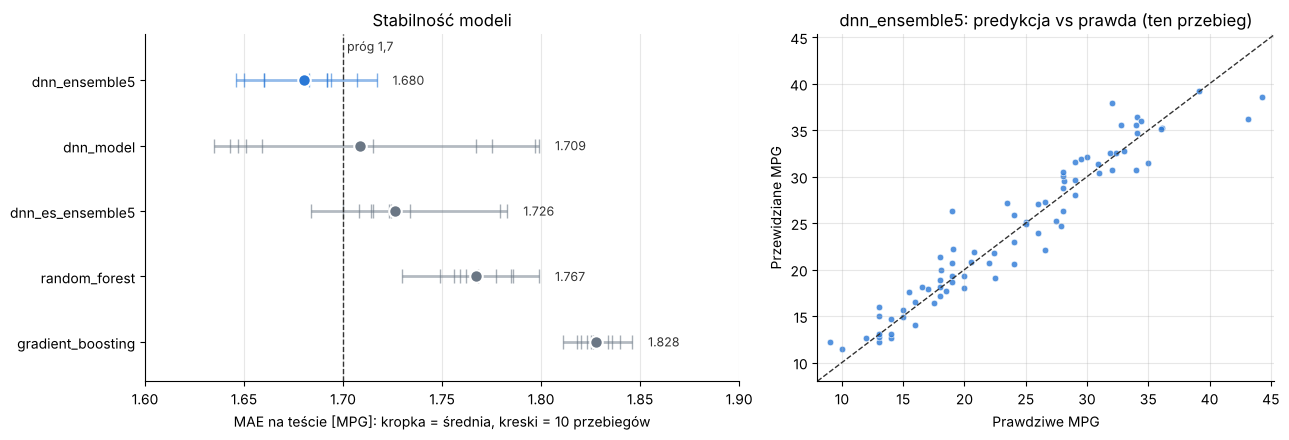

In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})

# lewy: średni MAE z 10 powtórzeń z zakresem min–max (tylko modele z pomiarem powtórzeń)
order = sorted(MEASURED_10_RUNS, key=lambda k: np.mean(MEASURED_10_RUNS[k]), reverse=True)
means = [np.mean(MEASURED_10_RUNS[k]) for k in order]
lo = [m - min(MEASURED_10_RUNS[k]) for k, m in zip(order, means)]
hi = [max(MEASURED_10_RUNS[k]) - m for k, m in zip(order, means)]
colors = ['#2a78d6' if k == 'dnn_ensemble5' else '#6b7785' for k in order]
for y, k in enumerate(order):   # wykres punktowy: oś nie startuje od zera, więc nie słupki
    v = MEASURED_10_RUNS[k]
    ax1.hlines(y, min(v), max(v), color=colors[y], lw=2, alpha=0.5)
    ax1.plot(v, [y] * len(v), '|', color=colors[y], ms=10, alpha=0.6)
    ax1.plot(np.mean(v), y, 'o', color=colors[y], ms=9, markeredgecolor='white', markeredgewidth=1.5)
    ax1.text(max(v) + 0.008, y, f'{np.mean(v):.3f}', va='center', fontsize=9, color='#333')
ax1.set_yticks(range(len(order)), order)
ax1.axvline(1.7, color='#333', ls='--', lw=1)
ax1.text(1.702, len(order) - 0.55, 'próg 1,7', fontsize=9, color='#333')
ax1.set_ylim(-0.6, len(order) - 0.3)
ax1.set_xlim(1.6, 1.9)
ax1.set_xlabel('MAE na teście [MPG]: kropka = średnia, kreski = 10 przebiegów')
ax1.set_title('Stabilność modeli')
ax1.spines[['top', 'right']].set_visible(False); ax1.grid(axis='x', alpha=0.3)

p = dnn_ensemble.predict(X_test)
ax2.scatter(y_test, p, s=22, color='#2a78d6', alpha=0.8, edgecolor='white', linewidth=0.5)
lim = [min(y_test.min(), p.min()) - 1, max(y_test.max(), p.max()) + 1]
ax2.plot(lim, lim, color='#333', lw=1, ls='--')
ax2.set_xlim(lim); ax2.set_ylim(lim)
ax2.set_xlabel('Prawdziwe MPG'); ax2.set_ylabel('Przewidziane MPG')
ax2.set_title('dnn_ensemble5: predykcja vs prawda (ten przebieg)')
ax2.spines[['top', 'right']].set_visible(False); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [62]:
pd.DataFrame(test_result, index=['Mean absolute Error [MPG]']).T.sort_values('Mean absolute Error [MPG]')

,Mean absolute Error [MPG]
dnn_ensemble5,1.715742
dnn_model,1.729964
random_forest,1.761169
dnn_es_ensemble5,1.781222
gradient_boosting,1.818582
dnn_model_big,2.436052
linear_model,2.462584
dnn_horsepower_model,2.913683
horsepower_model,3.644830
